In [1]:
%pip install geopandas libpysal spreg esda statsmodels matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [11]:
# First we will import all packages needed
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import libpysal

# From the packages we use some functions to use as shortcuts, including the OLS model commonly used in econometrics
from libpysal.weights import Queen
from libpysal import examples
from esda import Moran
from statsmodels.api import OLS, add_constant
from spreg import ML_Error

# libpysal has accessible datasets
# We use one on houssing values, which is a common topic in econometrics
# In the data, the important variables are the housing value (HOVAL), income and crime measure
# And not to forget the spatial data!
shapefile = examples.get_path("columbus.shp")
data = gpd.read_file(shapefile)

# Start with discarding the incomplete obsrvations
data = data.dropna(subset=["HOVAL", "INC", "CRIME"]).copy()

# Continue with analyzing the sshape of the data
print(data.head())
print(data.columns.tolist())
print("Number of neighbourhoods:", len(data))

# For our analysis we construct a spatial weights matrix using the function Queen
w = Queen.from_dataframe(data)
w.transform = "r"

       AREA  PERIMETER  COLUMBUS_  COLUMBUS_I  POLYID  NEIG      HOVAL  \
0  0.309441   2.440629          2           5       1     5  80.467003   
1  0.259329   2.236939          3           1       2     1  44.567001   
2  0.192468   2.187547          4           6       3     6  26.350000   
3  0.083841   1.427635          5           2       4     2  33.200001   
4  0.488888   2.997133          6           7       5     7  23.225000   

      INC      CRIME      OPEN  ...  DISCBD          X          Y  NSA  NSB  \
0  19.531  15.725980  2.850747  ...    5.03  38.799999  44.070000  1.0  1.0   
1  21.232  18.801754  5.296720  ...    4.27  35.619999  42.380001  1.0  1.0   
2  15.956  30.626781  4.534649  ...    3.89  39.820000  41.180000  1.0  1.0   
3   4.477  32.387760  0.394427  ...    3.70  36.500000  40.520000  1.0  1.0   
4  11.252  50.731510  0.405664  ...    2.83  40.009998  38.000000  1.0  1.0   

    EW   CP   THOUS  NEIGNO                                           geometry  

C:\Users\lisir\AppData\Local\Temp\ipykernel_29492\3912582909.py:29: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = Queen.from_dataframe(data)


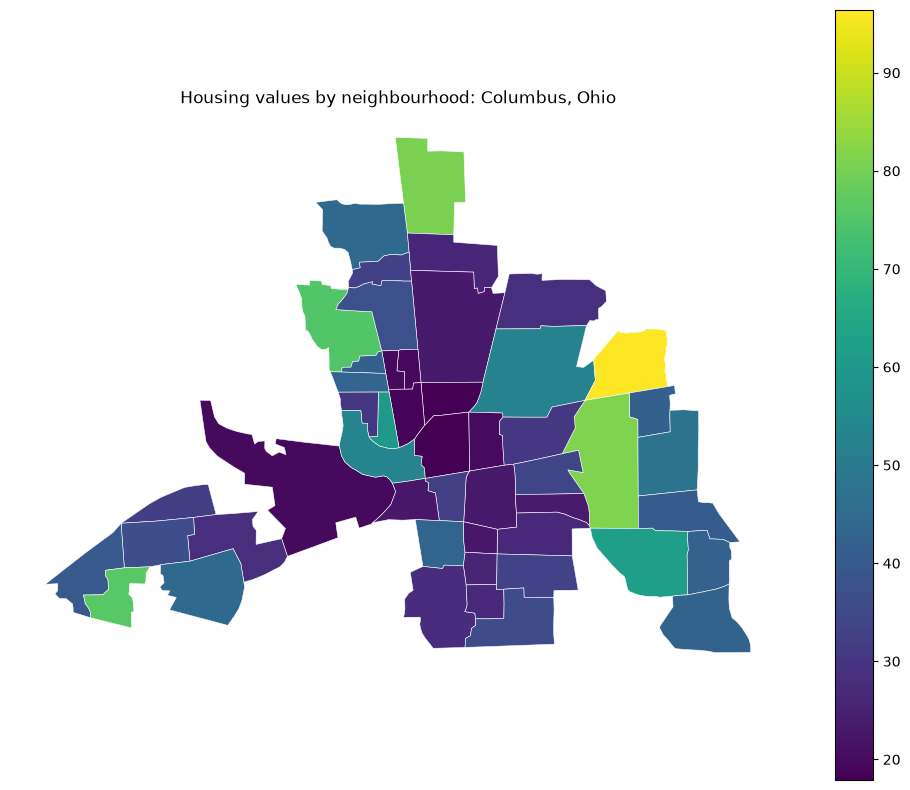

In [12]:
# In spatial science, we of course visualize our data by creating a map!

fig, ax = plt.subplots(figsize=(10, 8))

data.plot(
    column="HOVAL",
    cmap="viridis",
    legend=True,
    edgecolor="white",
    linewidth=0.4,
    ax=ax,
    missing_kwds={"color": "lightgrey"}
)

ax.set_title("Housing values by neighbourhood: Columbus, Ohio")
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [13]:
# In spatial science, spatial autocorrelation is measured by Moran's I
# A higher Moran's I would suggests more autocorrelation, while a lower Moran's I denotes dispersed behaviour
# We also print the corresponding p-value to denote its significance where we use an alpha of 0.05
moran_hoval = Moran(
    data["HOVAL"].to_numpy(),
    w,
    permutations=999
)

print("Moran's I:", round(moran_hoval.I, 4))
print("Permutation p-value:", round(moran_hoval.p_sim, 4))

Moran's I: 0.1801
Permutation p-value: 0.03


In [14]:
# We will now perform analysis on the data using an OLS model, with HOVAL being the dependent variable and income and crime being explanatory variables
y = data["HOVAL"]

X = data[["INC", "CRIME"]]
# Here we introduce the error term in the model
X_ols = add_constant(X)

# We perform the OLS model
ols = OLS(y, X_ols).fit()

# Print the results of the model
print(ols.summary())

# We will save the fitted values and residuals from the OLS model to further analyze spatial autocorrelation
data["ols_fitted"] = ols.fittedvalues
data["ols_residual"] = ols.resid

                            OLS Regression Results                            
Dep. Variable:                  HOVAL   R-squared:                       0.350
Model:                            OLS   Adj. R-squared:                  0.321
Method:                 Least Squares   F-statistic:                     12.36
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           5.06e-05
Time:                        21:14:06   Log-Likelihood:                -201.37
No. Observations:                  49   AIC:                             408.7
Df Residuals:                      46   BIC:                             414.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.4282     13.192      3.519      0.0

In [15]:
# We will now again apply Moran's I, but now to the fitted values and residuals of the data obtained from the OLS model
moran_resid = Moran(
    data["ols_residual"].to_numpy(),
    w,
    permutations=999
)

# We again print Moran's I and the corresponding p-value
print("Moran's I for OLS residuals:", round(moran_resid.I, 4))
print("Permutation p-value:", round(moran_resid.p_sim, 4))

Moran's I for OLS residuals: 0.1713
Permutation p-value: 0.031


In [16]:
# We will now construct a new model that explicitly takes spatial dependence into consideration in the error term

y_array = data[["HOVAL"]].to_numpy()
X_array = data[["INC", "CRIME"]].to_numpy()

# We use the predefined function ML_Error for this
spatial_error = ML_Error(
    y_array,
    X_array,
    w,
    name_y="HOVAL",
    name_x=["INC", "CRIME"]
)

print(spatial_error.summary)

ML_Error
REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ML SPATIAL ERROR (METHOD = full)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     unknown
Dependent Variable  :       HOVAL                Number of Observations:          49
Mean dependent var  :     38.4362                Number of Variables   :           3
S.D. dependent var  :     18.4661                Degrees of Freedom    :          46
Pseudo R-squared    :      0.3495
Log likelihood      :         nan
Sigma-square ML     :    237.8274                Akaike info criterion :         nan
S.E of regression   :     15.4217                Schwarz criterion     :         nan

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
-----------------------------------------------------------------------------------

C:\Users\lisir\anaconda3\Lib\site-packages\spreg\ml_error.py:184: RuntimeWarning: Method 'bounded' does not support relative tolerance in x; defaulting to absolute tolerance.
  res = minimize_scalar(
C:\Users\lisir\anaconda3\Lib\site-packages\spreg\ml_error.py:563: RuntimeWarning: invalid value encountered in log
  jacob = np.log(np.linalg.det(a))


In [17]:
# Construct a data frame to compare the two models
comparison = pd.DataFrame({
    "OLS coefficient": ols.params[["const", "INC", "CRIME"]],
    "OLS standard error": ols.bse[["const", "INC", "CRIME"]],
    "OLS p-value": ols.pvalues[["const", "INC", "CRIME"]],
})

# Obtain the coefficient values from the results of the spatial model
spatial_names = ["CONSTANT", "INC", "CRIME"]
spatial_betas = np.asarray(spatial_error.betas).flatten()

# Store the indexes and their corresponding betas
spatial_coef = pd.Series(
    spatial_betas[:3],
    index=["const", "INC", "CRIME"]
)

# Add a column to the comparison dataframe denoting the coefficients in the model including a spatial error coefficients
comparison["Spatial error coefficient"] = spatial_coef

print(comparison.round(4))

       OLS coefficient  OLS standard error  OLS p-value  \
const          46.4282             13.1918       0.0010   
INC             0.6290              0.5359       0.2466   
CRIME          -0.4849              0.1827       0.0109   

       Spatial error coefficient  
const                    45.2719  
INC                       0.6085  
CRIME                    -0.4448  


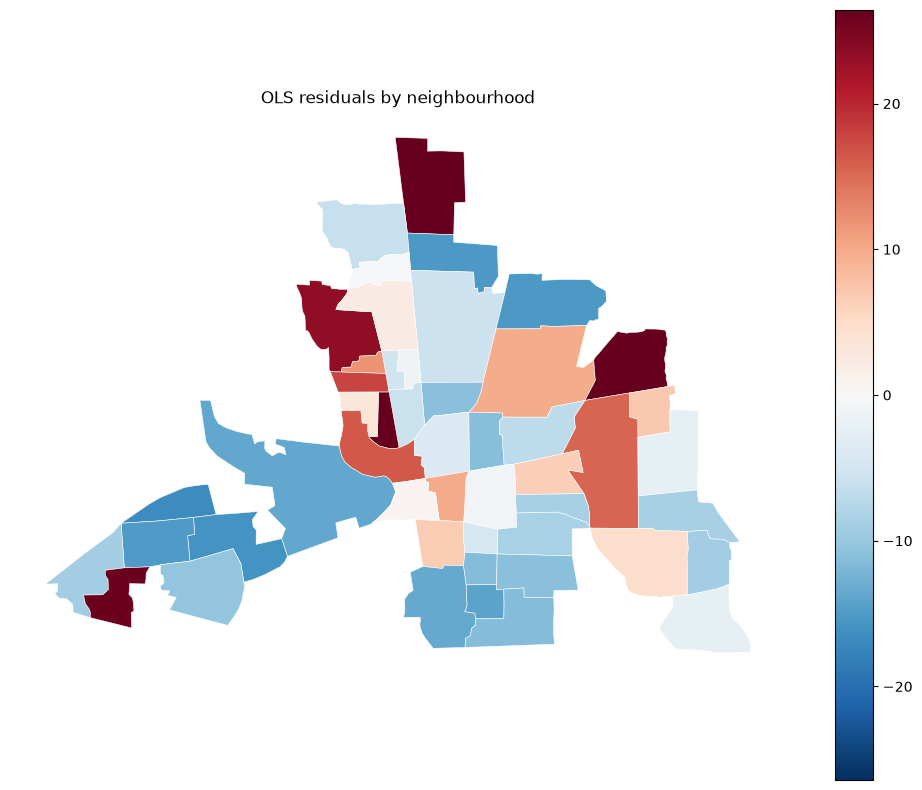

In [18]:
# Here we plot the OLS residuals on a map
fig, ax = plt.subplots(figsize=(10, 8))

limit = np.nanquantile(
    np.abs(data["ols_residual"]),
    0.95
)

data.plot(
    column="ols_residual",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    legend=True,
    edgecolor="white",
    linewidth=0.4,
    ax=ax
)

ax.set_title("OLS residuals by neighbourhood")
ax.set_axis_off()

plt.tight_layout()
plt.show()

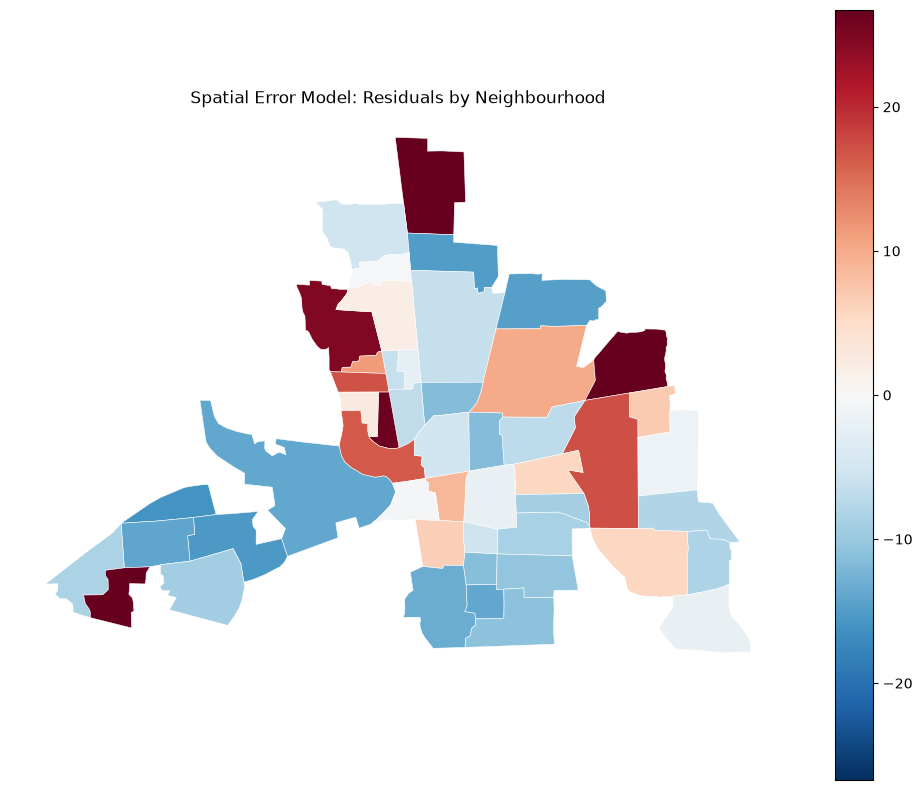

In [21]:
# Extract the estimated coefficients from the model
betas = np.asarray(spatial_error.betas).flatten()

# Obtain data on the intercept/constant and the explanatory variables
X_with_constant = np.column_stack([
    np.ones(len(data)),
    data[["INC", "CRIME"]].to_numpy()
])

# Obtain data on the dependent variable
y_observed = data["HOVAL"].to_numpy()

# Obtain the residuals from the model
data["sem_residual"] = (
    y_observed - X_with_constant @ betas[:3]
)

# We use the same colour scale as for the OLS residuals
limit = max(
    np.nanquantile(np.abs(data["ols_residual"]), 0.95),
    np.nanquantile(np.abs(data["sem_residual"]), 0.95)
)

# Plot the spatial error residuals on a map
fig, ax = plt.subplots(figsize=(10, 8))

data.plot(
    column="sem_residual",
    cmap="RdBu_r",
    vmin=-limit,
    vmax=limit,
    legend=True,
    edgecolor="white",
    linewidth=0.4,
    ax=ax
)

ax.set_title(
    "Spatial Error Model: Residuals by Neighbourhood"
)
ax.set_axis_off()

plt.tight_layout()
plt.show()